# Three answers for one jaw: the particle simulation, the population balance with a jaw capacity model and the measurement, at the three feeds of the laboratory tests

**Question:** At the three feeds measured, which is nearer the measurement, the particle simulation or the population balance with a jaw capacity model, and why?

- **Level:** 3, comparison with published methods
- **Prerequisites:** notebooks 01 and 02 of this topic; topics 03 and 04 for the population balance and the capacity model
- **Reading time:** about 100 minutes (the live batch takes about half a minute)

## Objectives

By the end of this notebook you can:

- compute by hand the capacity of a jaw crusher from the equations of Sastri (1994) and hold the result to the product's laboratory-jaw module, and say what the classification of the population balance assumes and what published range bounds it;
- follow the Whiten solve of the product's module on one feed, and turn the measured energy per tonne into the work index that Bond's law would need;
- read the committed document of the three sides at the three feeds, field by field: what a side holds, what a verdict holds, what its band and its basis say and when a verdict is resolved;
- say, from numbers, which side is nearer the measurement at each feed and each quantity, which verdicts are met and which are not, and what the document, the package's record and the cited sources support as the reason for the differences;
- say where the comparison breaks, in the runs that did not complete and in the sensitivity of the population balance to its three classification parameters, and run the same module on another jaw.

## Setup

The environment is that of notebooks 01 and 02: the published package `crushdem` 0.6.0 with its compiled kernels, which runs the live batch and gives the comparison protocol, and the product's laboratory-jaw module, imported by path from the pipeline.

```bash
pip install "crushdem[jit]==0.6.0" numba==0.68.1 llvmlite==0.50.0 numpy==2.4.6 matplotlib==3.11.2
```

The cell prints the versions and imports, besides the case and the protocol of the package, the module `labjaw` with the capacity model and the evaluation of a narrow feed, Bond's term, the classification curve and the stage's folder rule.

In [1]:
# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import collections
import contextlib
import importlib.metadata as md
import io
import json
import math
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('crushdem', 'numba', 'llvmlite', 'numpy', 'matplotlib'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline is imported by its path
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
# Public functions only: the notebook defines no method of its own
from crushdem import comparison
from crushdem.breakage import median_fracture_energy
from crushdem.cases import barrios2020 as case
from pipeline.dem import points as P
from pipeline.model.crusher import labjaw
from pipeline.model.crusher.breakage import BETA, GAMMA, specific_energy, t10_of
from pipeline.model.crusher.capacity import bond_power
from pipeline.model.crusher.classification import classify
from pipeline.stages import dem as stage
plt.rcParams.update({"figure.figsize": (8.6, 3.8), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

crushdem 0.6.0
numba 0.68.1
llvmlite 0.50.0
numpy 2.4.6
matplotlib 3.11.2


## Data

The measurements are those of Barrios, Jimenez-Herrera, Fuentes-Torres and Tavares (2020), https://doi.org/10.3390/min10080717, CC BY 4.0, as notebook 01 describes them. The three sides are in one file of this repository, `data/derived/dem/jaw-lab.json`, the document of the catalog row `dem-run` (schema `docs/contracts/schemas/dem-run.schema.json`, version 1.0.0), baked by `data-pipeline/run.py dem` from `crushdem` 0.6.0: for each of the three operating points (the feeds 63/52, 31.5/26.5 and 16/13.2 mm at 6.0 Hz and a closed side of 7.5 mm) it holds `measured`, `simulation` (the full-size run of 6 kg), `population_balance` (the laboratory-jaw module) and `verdicts`. A verdict compares two sides of a point on one quantity against a band set before any run: throughput within 10 percent, net power within 30 percent and reduction ratio, the feed F80 over the product P80, within 15 percent.

The cell reads the document and prints its state, the bands and the keys of a point.

In [2]:
# The committed document of the bake: the three sides at the three operating points, and its state
doc = json.loads((ROOT / "data/derived/dem/jaw-lab.json").read_text(encoding="utf-8"))
points = {p["feed_class"]: p for p in doc["points"]}
feeds = list(points)
bands = doc["bands"]
print("state:", doc["state"], "| incomplete runs:", doc["incomplete"], "| schema:", doc["schema"])
print("bands set before the runs (throughput, net power, reduction ratio):",
      bands["throughput_relative"], bands["net_power_relative"], bands["reduction_ratio_relative"])
print("keys of a point:", list(points["63/52"]))
print("keys of its verdicts:", list(points["63/52"]["verdicts"]))

state: partial | incomplete runs: ['31.5-26.5'] | schema: chancadem.dem.run/v1
bands set before the runs (throughput, net power, reduction ratio): 0.1 0.3 0.15
keys of a point: ['id', 'feed_class', 'feed_mm', 'feed_mean_mm', 'feed_f80_mm', 'measured', 'paper_simulation', 'simulation', 'population_balance', 'verdicts']
keys of its verdicts: ['simulation_vs_measured', 'population_balance_vs_measured', 'population_balance_vs_simulation']


The state of the document is `partial`: one of the three particle runs did not complete, and `incomplete` names it, the 31.5/26.5 mm feed (its point id writes the feed with a hyphen). Every other field is present, so the document is read as it is and nothing in this notebook fills a value the document leaves empty. The next cell prints one verdict as the document writes it, for the throughput of the particle simulation at the coarse feed.

In [3]:
# One verdict as the document writes it, for the throughput of the particle simulation of the coarse feed
verdict = points["63/52"]["verdicts"]["simulation_vs_measured"]["throughput"]
for key, value in verdict.items():
    shown = round(value, 4) if isinstance(value, float) else value
    print(f"{key:>16s}: {shown}")

           first: 2167.06
          second: 798.662
  relative_error: 1.7134
            band: 0.1
         verdict: not met
           basis: None
        resolved: True
edge_distance_se: 25.5701


The fields read as follows. `first` is the value of the first side of the pair, here the simulated throughput of 2167.06 kg/h, and `second` the value of the second, the measured 798.662 kg/h. The `relative_error` is $(first - second)/second$, +1.7134, that is +171 percent. The `band` is 0.1, so the verdict is `not met` (the absolute error exceeds the band). `basis` is empty when a number decided the verdict and names the reason when none could (`run_incomplete`, `no_work_index`, `nothing_passed`, `no_window`). `resolved` says whether the scatter of the strokes can explain the difference: it is true when the nearer band edge lies more than two standard errors from the window mean, and here it lies 25.5701 standard errors away (`edge_distance_se`), so the miss is not noise of one window. `resolved` exists only for the verdicts that rest on a window statistic, the two that compare the simulation with the measurement, and is empty for all others. The document also carries, at the coarse feed only, `paper_simulation`: the source paper's own simulated net power and throughput with the source string of each; it is context for the reader and enters no verdict.

## Method

Three sides answer the same question at each point. The measurement is the paper's. The particle simulation is the discrete element method with particle replacement of Cleary and Sinnott (2015) and Barrios et al. (2020) as `crushdem` 0.6.0 implements it, whose steps notebook 02 takes apart. It is not the paper's own simulation: it breaks spheres with the energy model of Tavares (2022) and an ore derived from the paper's single-particle tests, where the paper used a threshold force and a fixed set of daughters, and it runs with the contact of the paper's Table 3. The paper's own result is set beside the measurement in the comparison. The population balance is the product's engine, the Whiten model of topic 03, specialised to the laboratory jaw by a module that holds the jaw capacity model of Sastri (1994), a classification first estimate with ranges from the literature and a link to the ore. Nothing in that module is fitted to any measurement of the laboratory jaw: a test of the product reads its source for measured values and finds none. The steps below run it by hand and through the module, and then the particle simulation.

### Step 1: the jaw capacity model

Sastri (1994) reworks the laboratory data of Hersam into a volumetric capacity. With $G$ the gape, $S$ the closed side setting, $T$ the throw, $w$ the width, $N$ the strokes per minute and $D$ the depth between the jaws, all lengths in metres,

$$D = 3.25\,G^{1.15}, \qquad N_c = 66.4\left[\frac{G-(S+T)}{D\,T}\right]^{1/2}, \qquad V_h = 60\,N\,w\left(S+\frac{T}{2}\right)a, \qquad a = \frac{D\,T}{G-(S+T)}\ \ (N<N_c),$$

where $N_c$ is the critical speed and $a$ the height of the prism of rock that falls per stroke below it; above $N_c$ the prism is $a = 450\,g/N^2$. The capacity in t/h is

$$W = V_h\,K_1K_2K_3\,d, \qquad K_1 = 0.85 - \left(\frac{F_{av}}{G}\right)^{2.5}, \qquad K_2 = 1.92\times 10^{-6.5\,T/G},$$

with $d$ the density in t/m$^3$, $F_{av}$ the mean of the limits of the feed class and $K_3 = 1.0$ for hard rock (these $K$ are Sastri's capacity factors, not the classification parameters of the next step). The cell computes every term for the 63/52 mm feed by hand and calls the module.

In [4]:
# Step 1: Sastri's capacity of the jaw for the 63/52 mm feed, term by term by hand, against the product's module
jaw = labjaw.OTSUKA_BARRIOS_2020
gape, width, css, throw = jaw.gape_mm / 1000, jaw.width_mm / 1000, P.CSS_MM / 1000, P.THROW_MM / 1000
speed, density = P.SPEED_RPM, jaw.density_t_m3
f_av = labjaw.class_mean_mm(52.0, 63.0) / 1000
depth = 3.25 * gape**1.15
n_crit = 66.4 * math.sqrt((gape - (css + throw)) / (depth * throw))
prism = depth * throw / (gape - (css + throw))
vh = 60.0 * speed * width * (css + throw / 2.0) * prism
k1 = 0.85 - (f_av / gape) ** 2.5
k2 = 1.92 * 10.0 ** (-6.5 * throw / gape)
by_hand = vh * k1 * k2 * jaw.material_k3 * density * 1000.0
cap = labjaw.jaw_capacity_tph(speed, width, css, throw, gape, f_av, density, jaw.material_k3)
print(f"D = {depth:.4f} m, Nc = {n_crit:.1f} rpm against N = {speed:.0f} rpm (branch {cap.branch}), a = {prism:.4f} m")
print(f"Vh = {vh:.4f} m3/h, K1 = {k1:.4f}, K2 = {k2:.4f}, K3 = {jaw.material_k3}")
print(f"W by hand {by_hand:.2f} kg/h, product's module {cap.w_tph * 1000:.2f} kg/h")
high = 60.0 * speed * width * (css + throw / 2.0) * 450.0 * 9.81 / speed**2
print(f"the other branch (equation 6, high speed) would give {high * k1 * k2 * density * 1000.0:.2f} kg/h")

D = 0.2038 m, Nc = 396.0 rpm against N = 360 rpm (branch low-speed), a = 0.0281 m
Vh = 1.0627 m3/h, K1 = 0.5237, K2 = 0.3640, K3 = 1.0
W by hand 546.98 kg/h, product's module 546.98 kg/h
the other branch (equation 6, high speed) would give 662.72 kg/h


By hand the depth is 0.2038 m and the critical speed 396.0 rpm, above the 360 rpm of the jaw, so the low-speed branch applies and the prism has a height of 0.0281 m. The volumetric capacity is 1.0627 m$^3$/h, the feed factor $K_1$ is 0.5237 (the 57.5 mm mean feed is two thirds of the 90 mm gape) and the throw factor $K_2$ 0.3640, which gives 546.98 kg/h, the same 546.98 kg/h as the module. The other branch, equation 6 for speeds above critical, would give 662.72 kg/h; the printed rule picks the branch by the critical speed and the module follows it, so the choice is not the notebook's. The next cell evaluates the model at the three feeds beside the document and the measurement.

In [5]:
# The capacity at the three feeds, the jaw capacity model beside the document and the measurement
print("feed [mm]  K1 of the feed  model [kg/h]  document [kg/h]  measured [kg/h]  error")
for fc, pt in points.items():
    mean_m = labjaw.class_mean_mm(*pt["feed_mm"]) / 1000
    c3 = labjaw.jaw_capacity_tph(speed, width, css, throw, gape, mean_m, density, jaw.material_k3)
    measured_q = pt["measured"]["throughput_kg_h"]["value"]
    error = (c3.w_tph * 1000 - measured_q) / measured_q
    doc_q = pt["population_balance"]["throughput_kg_h"]
    print(f"{fc:>10s} {c3.k1:14.4f} {c3.w_tph * 1000:13.2f} {doc_q:16.2f} {measured_q:15.1f} {error:+8.3f}")

feed [mm]  K1 of the feed  model [kg/h]  document [kg/h]  measured [kg/h]  error
     63/52         0.5237        546.98           546.98           798.7   -0.315
 31.5/26.5         0.7911        826.17           826.17           937.2   -0.118
   16/13.2         0.8394        876.65           876.65          1220.4   -0.282


The module and the document agree to the last digit at the three feeds: 546.98, 826.17 and 876.65 kg/h, against 798.7, 937.2 and 1220.4 kg/h measured, errors of -0.315, -0.118 and -0.282. The model is below the measurement at every feed, by 31.5, 11.8 and 28.2 percent. Sastri's own check on Hersam's data reports "deviations of less than 20 percent in most cases", so one feed of three is inside the accuracy its author states for it.

### Step 2: the classification and the ranges that bound it

The Whiten model sends to breakage a share $C(d)$ of the particles of size $d$ (Whiten, 1972). Its classification curve has three parameters:

$$C(d) = \begin{cases} 0 & d \le K_1 \\ 1 - \left(\dfrac{K_2 - d}{K_2 - K_1}\right)^{K_3} & K_1 < d < K_2 \\ 1 & d \ge K_2 \end{cases}$$

with $K_1$ the size below which nothing is caught, $K_2$ the size above which everything is and $K_3$ the shape of the curve between them. No constant of a laboratory jaw has been published, so the module takes the first estimate of Donovan (2003, section 2.1.3): $K_1$ the closed side setting, $K_2$ near the open side setting and $K_3$ = 2.3, and bounds it with the ranges that King (2000) gives for standard and short-head Symons cone crushers, used here for a laboratory jaw for want of published jaw values, $K_1 = \alpha_1\,\mathrm{CSS}$ with $\alpha_1$ from 0.5 to 0.95, $K_2 = \alpha_2\,\mathrm{CSS}$ with $\alpha_2$ from 1.7 to 3.5 and $K_3$ from 1 to 3. The cell prints both.

In [6]:
# Step 2: the classification first estimate and the cone-crusher ranges that bound it
estimate = labjaw.lab_classification(P.CSS_MM, P.THROW_MM)
ranges = labjaw.KING_RANGES
k1_lo, k1_hi = (a * P.CSS_MM for a in ranges.alpha1)
k2_lo, k2_hi = (a * P.CSS_MM for a in ranges.alpha2)
print(f"first estimate: K1 = {estimate.k1} mm, K2 = {estimate.k2} mm, K3 = {estimate.k3}")
print(f"ranges of King (2000) for cone crushers: K1 = {k1_lo:.2f} to {k1_hi:.2f} mm,",
      f"K2 = {k2_lo:.2f} to {k2_hi:.2f} mm,",
      f"n = {ranges.n[0]:g} to {ranges.n[1]:g}")
floor = labjaw.K2_FLOOR_OVER_K1 * estimate.k1
print(f"the engine's floor, K2 at least {labjaw.K2_FLOOR_OVER_K1} K1, is {floor:.3f} mm and does not bind here")

first estimate: K1 = 7.5 mm, K2 = 17.5 mm, K3 = 2.3
ranges of King (2000) for cone crushers: K1 = 3.75 to 7.12 mm, K2 = 12.75 to 26.25 mm, n = 1 to 3
the engine's floor, K2 at least 1.05 K1, is 7.875 mm and does not bind here


The first estimate gives $K_1$ = 7.5 mm and $K_2$ = 17.5 mm, the closed and the open side, with $K_3$ = 2.3. King's cone-crusher ranges put $K_1$ between 3.75 and 7.12 mm and $K_2$ between 12.75 and 26.25 mm: the first estimate lies outside the range of $K_1$ ($\alpha_1$ = 1 against at most 0.95) and inside the range of $K_2$. The sweep below moves $\alpha_1$ inside King's range while the reported model uses 1.0, so it measures a sensitivity around a point at the edge of the range and not an uncertainty of the model. The engine also keeps $K_2$ at least 1.05 $K_1$, a floor of 7.875 mm, which does not bind here.

### Step 3: the Whiten solve and the link to the ore

The product is the solution of the Whiten balance on the engine's sieve grid,

$$\mathbf p = (\mathbf I - \mathbf C)\,(\mathbf I - \mathbf B\,\mathbf C)^{-1}\,\mathbf f,$$

with $\mathbf f$ the feed mass by size class, $\mathbf C$ the diagonal matrix of $C(d)$ and $\mathbf B$ the breakage matrix built from $t_{10}$ (Whiten, 1972). The $t_{10}$ follows the JKMRC form $t_{10} = A\,[1 - \exp(-b\,E_{cs})]$ at the engine's specific energy per nip, $E_{cs} = 0.033\,T\,(N/350)$ kWh/t, with $T$ the throw in mm and $N$ the strokes per minute: a rule written for the cone engine and applied here unchanged to the laboratory jaw. The breakage matrix then follows the Austin form (Austin, Klimpel and Luckie, 1984), $B(u) = \varphi\,u^{\gamma} + (1-\varphi)\,u^{\beta}$ for the relative size $u$, with $\gamma$ = 0.35 and $\beta$ = 4.2 fixed by the engine and $\varphi$ solved so that $B(1/10) = t_{10}$, and with $t_{10}$ capped at 0.44. The ore enters through $A\,b$, which the product gets from the particle simulation's own ore by equating the exponents of the two published $t_{10}$ laws, $A\,b = 3600\,A\,b'/E_{50}$ with $E_{50}$ the median fracture energy at the feed's mean size. That equation is the product's algebra and not a published conversion, and it makes $b$ depend on size where the engine holds it constant. The engine also takes $A$ = 60 in the JKMRC form where the link uses the ore's own $A$ of 59.7, a small inconsistency that the cell after the next one quantifies. The cell evaluates each feed.

In [7]:
# Step 3: the ore link and the Whiten solve for each feed, through the product's laboratory-jaw module
ore, derivation = case.paper_ore("A", seed=1)
print("feed [mm]  E50 [J/kg]    A*b   t10 [%]  F80 [mm]  P80 [mm]  P50 [mm]  reduction ratio  mass closure")
results = {}
for fc, pt in points.items():
    lo, hi = pt["feed_mm"]
    e50 = median_fracture_energy(labjaw.class_mean_mm(lo, hi) / 1000.0, ore)
    axb = labjaw.axb_from_fracture_energy(ore.a_max, ore.b_prime, e50)
    r = labjaw.evaluate_lab_jaw(jaw, lo, hi, P.CSS_MM, P.SPEED_RPM, axb)
    results[fc] = r
    print(f"{fc:>10s} {e50:11.1f} {axb:6.1f} {100 * r.t10:8.3f} {r.f80_mm:9.2f} {r.p80_mm:9.2f} {r.p50_mm:9.2f}",
          f"{r.reduction_ratio:15.3f} {sum(r.product.mass):12.6f}")

feed [mm]  E50 [J/kg]    A*b   t10 [%]  F80 [mm]  P80 [mm]  P50 [mm]  reduction ratio  mass closure
     63/52        26.6  201.9   40.856     61.24      5.88      1.90          10.415     1.000000
 31.5/26.5        58.2   92.3   24.402     30.68      6.99      2.47           4.387     1.000000
   16/13.2       168.6   31.9    9.897     15.55     10.34      7.08           1.504     1.000000


The median fracture energies 26.6, 58.2 and 168.6 J/kg give $A\,b$ of 201.9, 92.3 and 31.9, and $t_{10}$ of 40.856, 24.402 and 9.897 percent: the weak coarse feed breaks fine and the strong fine feed barely breaks. The products have a P80 of 5.88, 6.99 and 10.34 mm for feeds whose F80 is 61.24, 30.68 and 15.55 mm, reduction ratios of 10.415, 4.387 and 1.504, and the mass closes (1.000000). The next cell shows the rule that sets those $t_{10}$ values.

In [8]:
# The engine's own rule for the energy per nip and for the breakage function, applied unchanged to the laboratory jaw
e_cs = specific_energy(P.SPEED_RPM, P.THROW_MM)
print(f"E_cs = 0.033 T (N / 350) = {e_cs:.4f} kWh/t, at T = {P.THROW_MM:g} mm and N = {P.SPEED_RPM:g} rpm")
print(f"Austin slopes of the engine: gamma = {GAMMA}, beta = {BETA}; t10 capped at 0.44;",
      f"engine A = 60, ore link A = {ore.a_max}")
e50_coarse = median_fracture_energy(labjaw.class_mean_mm(*points["63/52"]["feed_mm"]) / 1000.0, ore)
axb_coarse = labjaw.axb_from_fracture_energy(ore.a_max, ore.b_prime, e50_coarse)
t10_engine = 100 * t10_of(e_cs, axb_coarse)
t10_same_a = ore.a_max * (1.0 - math.exp(-axb_coarse / ore.a_max * e_cs))
print(f"coarse feed, t10 with the engine's A = 60: {t10_engine:.3f} %; with the ore's A throughout: {t10_same_a:.3f} %")

E_cs = 0.033 T (N / 350) = 0.3394 kWh/t, at T = 10 mm and N = 360 rpm
Austin slopes of the engine: gamma = 0.35, beta = 4.2; t10 capped at 0.44; engine A = 60, ore link A = 59.7
coarse feed, t10 with the engine's A = 60: 40.856 %; with the ore's A throughout: 40.761 %


The engine's rule gives $E_{cs}$ = 0.3394 kWh/t at a throw of 10 mm and 360 strokes per minute. It is a per-nip rule written for the cone engine and referenced to 350 rpm, applied here unchanged to the laboratory jaw: a modelling choice and not a property of the jaw. With the engine's $A$ = 60 the coarse feed's $t_{10}$ is 40.856 percent and with the ore's $A$ of 59.7 throughout it would be 40.761, a difference of 0.095 points that does not change the reading. The next cell opens the coarse feed's solve: the classification curve at six sizes, the classes that hold feed mass and the product.

In [9]:
# The classification curve of the first estimate and the classes of the coarse feed and of its product
r = results["63/52"]
print("size d [mm]:", [5.0, 7.5, 10.0, 12.5, 15.0, 17.5])
print("C(d):", [round(classify(d, r.classification), 3) for d in (5.0, 7.5, 10.0, 12.5, 15.0, 17.5)])
fed = [(round(mid, 1), round(m, 4)) for mid, m in zip(r.feed.mid_mm, r.feed.mass) if m > 0]
print("classes with feed mass (mid size [mm], mass fraction):", fed)
below = sum(m for mid, m in zip(r.product.mid_mm, r.product.mass) if mid < P.CSS_MM)
print(f"product mass below the closed side {100 * below:.1f} %,",
      f"mass closure {abs(sum(r.product.mass) - sum(r.feed.mass)):.1e}")

size d [mm]: [5.0, 7.5, 10.0, 12.5, 15.0, 17.5]
C(d): [0.0, 0.0, 0.484, 0.797, 0.959, 1.0]
classes with feed mass (mid size [mm], mass fraction): [(53.8, 1.0)]
product mass below the closed side 90.6 %, mass closure 0.0e+00


The classification curve is zero at 5.0 and 7.5 mm, 0.484 at 10 mm, 0.797 at 12.5 mm, 0.959 at 15 mm and 1 at 17.5 mm. The whole feed, 52 to 63 mm, falls in one class of mid size 53.8 mm, far above $K_2$, so all of it is caught at the first pass, and 90.6 percent of the product mass ends below the closed side of 7.5 mm, with mass closure to round-off. The product of this model is therefore much finer than the closed side suggests for a single pass of rock this coarse, because the solve lets the broken mass return to the chamber and be caught again until it is smaller than $K_1$, where the breakage matrix leaves it.

### Step 4: Bond's size term and the work index the measurement implies

Bond's third law gives the energy to reduce a feed of size $F_{80}$ to a product of size $P_{80}$ (sizes in micrometres, Bond, 1952):

$$W = 10\,W_i\left(\frac{1}{\sqrt{P_{80}}} - \frac{1}{\sqrt{F_{80}}}\right) \quad [\mathrm{kWh/t}],$$

with $W_i$ the work index of the ore. No work index of the ore of Barrios et al. is published, so the population balance states no power. What can be computed is the size term, the energy per unit of work index, and the work index that the measured energy per tonne would imply with it. The cell computes the term with the measured P80 and with the model's, by hand and through the engine's function.

In [10]:
# Step 4: Bond's size term and the work index that the measured energy implies, with the measured and the modelled P80
print("feed [mm]  measured [kWh/t]  term, measured P80  Wi implied  term, model P80  Wi with model P80")
implied_measured, implied_model = [], []
for fc, pt in points.items():
    meas = pt["measured"]
    f80 = pt["feed_f80_mm"]
    term_meas = bond_power(1.0, f80, meas["p80_mm"], 1.0)
    term_model = bond_power(1.0, f80, results[fc].p80_mm, 1.0)
    by_hand_term = 10.0 * (1.0 / math.sqrt(meas["p80_mm"] * 1000.0) - 1.0 / math.sqrt(f80 * 1000.0))
    energy = meas["specific_energy_kwh_t"]
    implied_measured.append(energy / term_meas)
    implied_model.append(energy / term_model)
    print(f"{fc:>10s} {energy:15.3f} {term_meas:19.4f} {implied_measured[-1]:12.2f}",
          f"{term_model:16.4f} {implied_model[-1]:15.2f} (by hand {by_hand_term:.4f})")
print(f"implied work index, highest over lowest: {max(implied_measured) / min(implied_measured):.2f}",
      f"(measured P80), {max(implied_model) / min(implied_model):.2f} (model P80)")

feed [mm]  measured [kWh/t]  term, measured P80  Wi implied  term, model P80  Wi with model P80
     63/52           0.426              0.0781         5.45           0.0900            4.73 (by hand 0.0781)
 31.5/26.5           0.177              0.0574         3.08           0.0625            2.83 (by hand 0.0574)
   16/13.2           0.110              0.0328         3.36           0.0182            6.07 (by hand 0.0328)
implied work index, highest over lowest: 1.77 (measured P80), 2.15 (model P80)


The measured energy is 0.426, 0.177 and 0.110 kWh/t. With the measured P80 the Bond term is 0.0781, 0.0574 and 0.0328 (the by-hand value equals the engine's) and the implied work index 5.45, 3.08 and 3.36 kWh/t; with the model's P80 it is 4.73, 2.83 and 6.07. A single ore has one work index, and the three implied values differ by a factor of 1.77 with the measured P80, or 2.15 with the model's: Bond's size term does not reproduce how the measured energy falls with the feed, at this scale. The reason the population balance states no power at these points is the missing work index of the ore; the spread of the implied index is a second argument against inventing one to give it a power.

### Step 5: the particle simulation, live at each feed and at full size

The particle simulation is that of notebook 02. The compared protocol is a batch of 6 kg at each feed, which takes from minutes to over an hour per feed on the bake's machine (the command of the section on your own data reproduces it), so a notebook cannot run it. This one does two things. The live cell runs a reduced batch of 0.5 kg at each of the three feeds through the same call and the same settings as the full-size runs (the second rung of the stage's overlap ladder, 0.5, the stall rule, the seed and the particle slots of each point) and prints each live run beside the committed full-size run. The live values are small-batch values with no steady window: they show that the call runs and which way it points. The compared values, and the verdicts below, stay those of the committed 6 kg runs, which the cell after the live one reads.

In [11]:
# Step 5: the particle simulation live at each feed: 0.5 kg through the call and settings of the full-size runs
live = {}
for pt in P.POINTS:
    with contextlib.redirect_stdout(io.StringIO()):
        live[pt.feed_class] = case.run_attempt(ore, 0.5, P.FREQUENCY_HZ, P.SEED, pt.capacity, 0.5, P.BACKEND,
                                               P.MAX_STROKES, P.MAX_WALL_S, P.STALL_STROKES, feed_class=pt.feed_class)
print("feed  live 0.5 kg: status  strokes  overlap  balance residual [kg]  P80 [mm]  ratio",
      "| committed 6 kg: status  strokes  P80  ratio")
for fc, run in live.items():
    p80_live = comparison.d_percent(run["product"], 0.8)
    big = points[fc]["simulation"]
    print(f"{fc:>10s} {run['status']:>9s} {run['strokes']:7d} {run['max_overlap_reached']:8.3f}",
          f"{run['mass_balance_residual_kg']:12.1e}",
          f"{p80_live:11.2f} {points[fc]['feed_f80_mm'] / p80_live:6.2f} | {big['status']:>13s} {big['strokes']:7d}",
          f"{big['p80_mm']:6.2f} {big['reduction_ratio'] or float('nan'):6.2f}")
print("the live values are small-batch values with no steady window; the compared values are the committed ones")

feed  live 0.5 kg: status  strokes  overlap  balance residual [kg]  P80 [mm]  ratio | committed 6 kg: status  strokes  P80  ratio
     63/52  complete      13    0.328      2.4e-16       15.42   3.97 |      complete      83  14.68   4.17
 31.5/26.5  complete      10    0.359      4.3e-16       14.57   2.11 | overlap_error       5  14.63   2.10
   16/13.2  complete       6    0.313      3.0e-16       15.20   1.02 |      complete      54  15.25   1.02
the live values are small-batch values with no steady window; the compared values are the committed ones


The three live batches of 0.5 kg complete, in 13, 10 and 6 strokes, with largest overlaps of 0.328, 0.359 and 0.313 (above the 0.3 reference of the contact model, so they run only because their limit is 0.5), and close their mass balances to round-off (2.4e-16, 4.3e-16 and 3.0e-16 kg). Their P80 is 15.42, 14.57 and 15.20 mm and their reduction ratios 3.97, 2.11 and 1.02, close to the committed 6 kg values at the two feeds that completed (14.68 mm and 4.17; 15.25 mm and 1.02) and to the product of the stopped middle run (14.63 mm and 2.10, the product of a run that did not complete and not a compared value). The small batches therefore call the same code with the same settings and point the same way as the full-size runs: a product about twice as coarse as the measured P80 of 7.12, 7.62 and 7.83 mm. They have no steady window and nothing below is compared with them. The live batch of the middle feed completes where its 6 kg run stops with the overlap error.

In [12]:
# The full-size runs as the document records them: status, window, means with their standard errors, product and
# overlap
for fc, pt in points.items():
    s = pt["simulation"]
    print(f"{fc}: status {s['status']}, {s['strokes']} strokes, window {s['window']}")
    if s["window"] is None:
        print(f"      no window statistic; whole-run throughput {s['throughput_whole_run_kg_h']:.0f} kg/h,",
              f"{s['held_spheres']} spheres held")
        continue
    print(f"      throughput {s['throughput_kg_h']:.0f} +/- {s['throughput_se_kg_h']:.0f} kg/h,",
          f"net power {s['net_power_kw']:.4f} +/- {s['net_power_se_kw']:.4f} kW,",
          f"energy {s['specific_energy_j_kg']:.0f} J/kg, stationary: {s['power_trend_stationary']}")
    print(f"      P80 {s['p80_mm']:.2f} mm, reduction ratio {s['reduction_ratio']:.2f},",
          f"largest sphere {s['largest_product_mm']:.1f} mm, {s['spheres_above_open_side']} above the open side,",
          f"{s['window_strokes_above_overlap_reference']} window strokes above 0.3")

63/52: status complete, 83 strokes, window {'first_stroke': 37, 'last_stroke': 65, 'strokes': 29}
      throughput 2167 +/- 50 kg/h, net power 0.3009 +/- 0.0249 kW, energy 500 J/kg, stationary: True
      P80 14.68 mm, reduction ratio 4.17, largest sphere 18.1 mm, 9 above the open side, 18 window strokes above 0.3
31.5/26.5: status overlap_error, 5 strokes, window None
      no window statistic; whole-run throughput 1296 kg/h, 327 spheres held
16/13.2: status complete, 54 strokes, window {'first_stroke': 15, 'last_stroke': 39, 'strokes': 25}
      throughput 2464 +/- 47 kg/h, net power 0.1108 +/- 0.0085 kW, energy 162 J/kg, stationary: True
      P80 15.25 mm, reduction ratio 1.02, largest sphere 16.0 mm, 0 above the open side, 17 window strokes above 0.3


At full size the coarse feed completes in 83 strokes with a window of strokes 37 to 65 (29 strokes): a throughput of 2167 kg/h with a standard error of 50, a net power of 0.3009 kW with an error of 0.0249 (stationary), 500 J/kg, a P80 of 14.68 mm, a reduction ratio of 4.17 and a largest sphere of 18.1 mm, 9 of them above the 17.5 mm open side, with 18 of the 29 window strokes above an overlap of 0.3. The fine feed completes in 54 strokes (window 15 to 39): 2464 kg/h, 0.1108 kW, 162 J/kg, P80 15.25 mm, ratio 1.02, largest sphere 16.0 mm and 17 window strokes above 0.3. The middle feed stops after 5 strokes with 327 spheres held and has no window: only the whole-run throughput of 1296 kg/h is recorded, which is not comparable with a window statistic.

## Comparison

The comparison has three parts: every verdict of the document, a table of the quantities of the three sides at the three feeds with the nearer side, and a figure. The first cell prints the nine verdicts of each point and counts them by outcome and basis.

In [13]:
# The nine verdicts of every point: pair, quantity, error, band, verdict, basis and whether it is resolved
print("feed  pair  quantity  error  band  verdict  basis  resolved")
short = {"simulation_vs_measured": "sim-meas", "population_balance_vs_measured": "pb-meas"}
short["population_balance_vs_simulation"] = "pb-sim"
for fc, pt in points.items():
    for pair, group in pt["verdicts"].items():
        for quantity, v in group.items():
            err = "none" if v["relative_error"] is None else f"{v['relative_error']:+.3f}"
            print(f"{fc:>10s} {short[pair]:>9s} {quantity:>16s} {err:>7s} {v['band']:5.2f}",
                  f"{v['verdict']:>12s} {str(v['basis']):>15s} {str(v['resolved']):>6s}")
verdicts = [v for pt in points.values() for g in pt["verdicts"].values() for v in g.values()]
count = collections.Counter((v["verdict"], v["basis"]) for v in verdicts)
print({f"{a} / {b}": n for (a, b), n in count.items()})

feed  pair  quantity  error  band  verdict  basis  resolved
     63/52  sim-meas       throughput  +1.713  0.10      not met            None   True
     63/52  sim-meas        net_power  -0.115  0.30          met            None   True
     63/52  sim-meas  reduction_ratio  -0.515  0.15      not met            None   None
     63/52   pb-meas       throughput  -0.315  0.10      not met            None   None
     63/52   pb-meas        net_power    none  0.30 not compared   no_work_index   None
     63/52   pb-meas  reduction_ratio  +0.211  0.15      not met            None   None
     63/52    pb-sim       throughput  -0.748  0.10      not met            None   None
     63/52    pb-sim        net_power    none  0.30 not compared   no_work_index   None
     63/52    pb-sim  reduction_ratio  +1.496  0.15      not met            None   None
 31.5/26.5  sim-meas       throughput    none  0.10 not compared  run_incomplete   None
 31.5/26.5  sim-meas        net_power    none  0.30 not comp

Of the 27 verdicts, 13 are not met, 3 are met, 6 are not compared for want of a work index (every population balance power verdict) and 5 are not compared because the particle run did not complete. The three that are met are the two net power verdicts of the simulation, at the coarse feed (-0.115, resolved) and at the fine feed (-0.177, not resolved), and the reduction ratio of the population balance at the middle feed (+0.090). Everything else that can be computed is outside its band set before the runs: the simulation by +1.713 and +1.019 in throughput and by -0.515 and -0.487 in reduction ratio, the population balance by -0.315, -0.118 and -0.282 in throughput and by +0.211 and -0.243 in reduction ratio at the other two feeds. A verdict not met is reported as not met: the three bands were not widened after the runs.

The next cell tabulates the quantities that both a particle simulation and a population balance state, with the nearer side by absolute relative error.

In [14]:
# The comparison at the three feeds: throughput, P80 and reduction ratio of the three sides, and which side is nearer
print("quantity         feed      measured   simulation   population balance   nearer   error ratio sim/pb")
tally, ratios = collections.Counter(), []
for fc, pt in points.items():
    m, s, b = pt["measured"], pt["simulation"], pt["population_balance"]
    done = s["status"] == "complete"
    quantities = (("throughput [kg/h]", m["throughput_kg_h"]["value"], s["throughput_kg_h"], b["throughput_kg_h"]),
                  ("P80 [mm]", m["p80_mm"], s["p80_mm"], b["p80_mm"]),
                  ("reduction ratio", m["reduction_ratio"], s["reduction_ratio"], b["reduction_ratio"]))
    for label, measured_value, sim_value, pb_value in quantities:
        sim_value = sim_value if done else None
        errors = {"population balance": abs(pb_value - measured_value) / measured_value}
        ratio_text = ""
        if sim_value is not None:
            errors["simulation"] = abs(sim_value - measured_value) / measured_value
            ratios.append(errors["simulation"] / errors["population balance"])
            ratio_text = f"{ratios[-1]:.2f}"
        winner = min(errors, key=errors.get)
        tally[winner] += 1
        sim_text = "absent" if sim_value is None else f"{sim_value:.2f}"
        print(f"{label:>18s} {fc:>10s} {measured_value:10.2f} {sim_text:>12s} {pb_value:20.2f}",
              f"  {winner:<19s} {ratio_text:>6s}")
print(dict(tally), "error ratio from", f"{min(ratios):.2f}", "to", f"{max(ratios):.2f}")

quantity         feed      measured   simulation   population balance   nearer   error ratio sim/pb
 throughput [kg/h]      63/52     798.66      2167.06               546.98   population balance    5.44
          P80 [mm]      63/52       7.12        14.68                 5.88   population balance    6.09
   reduction ratio      63/52       8.60         4.17                10.41   population balance    2.44
 throughput [kg/h]  31.5/26.5     937.16       absent               826.17   population balance        
          P80 [mm]  31.5/26.5       7.62       absent                 6.99   population balance        
   reduction ratio  31.5/26.5       4.02       absent                 4.39   population balance        
 throughput [kg/h]    16/13.2    1220.44      2464.11               876.65   population balance    3.62
          P80 [mm]    16/13.2       7.83        15.25                10.34   population balance    2.95
   reduction ratio    16/13.2       1.99         1.02               

By absolute relative error the population balance is the nearer side in all 9 pairs of feed and quantity, 3 of them by default because the simulation has no completed run at the middle feed; in the 6 pairs where both sides exist it is nearer in 6 of 6. Nearer is not within the band: of the 6 pairs that carry a band (throughput and reduction ratio at each feed; P80 has none) the balance meets its band in 1, and the simulation's errors are 2.00 to 6.09 times those of the balance. The next cell prints the net power and the energy per kilogram, where only the simulation and the measurement speak.

In [15]:
# Net power and the energy per kilogram: the measurement, the simulation with its error, and the population balance
print("feed  measured [kW]  simulation [kW]  standard error [kW]  measured [J/kg]  simulation [J/kg]")
for fc, pt in points.items():
    s, m = pt["simulation"], pt["measured"]
    sim_power = "absent" if s["net_power_kw"] is None else f"{s['net_power_kw']:.4f}"
    sim_se = "absent" if s["net_power_se_kw"] is None else f"{s['net_power_se_kw']:.4f}"
    sim_energy = "absent" if s["specific_energy_j_kg"] is None else f"{s['specific_energy_j_kg']:.0f}"
    print(f"{fc:>10s} {m['net_power_kw']['value']:12.4f} {sim_power:>15s} {sim_se:>19s}",
          f"{m['specific_energy_j_kg']:15.0f} {sim_energy:>17s}")
print("population balance: states no power, because no work index of the ore is published")

feed  measured [kW]  simulation [kW]  standard error [kW]  measured [J/kg]  simulation [J/kg]
     63/52       0.3400          0.3009              0.0249            1533               500
 31.5/26.5       0.1656          absent              absent             636            absent
   16/13.2       0.1346          0.1108              0.0085             397               162
population balance: states no power, because no work index of the ore is published


The net power says something else. The simulation states 0.3009 kW at the coarse feed against 0.34 measured and 0.1108 kW at the fine feed against 0.1346, inside the 30 percent band, and the balance states none. But the energy per kilogram the machine draws is 500 and 162 J/kg in the simulation against 1533 and 397 measured, 67 and 59 percent low: the power lands near the measurement because the simulated machine passes the batch about 2.7 times and 2.0 times faster, which offsets an energy balance that is too low by about the same factor. The met power verdicts are not a sign that the energy balance is right.

The paper's own simulation is a further reference. The next cell sets it beside the measurement and beside the result of `crushdem` 0.6.0 at the one feed where the paper states it, with the source strings as the document gives them.

In [16]:
# The paper's own simulation, as the document records it for the coarse feed, beside the measurement and
# crushdem's run
coarse = points["63/52"]
paper = coarse["paper_simulation"]
sim_c = coarse["simulation"]
ours = {"net_power_kw": sim_c["net_power_kw"], "throughput_kg_h": sim_c["throughput_kg_h"]}
meas_c = coarse["measured"]
measured_now = {"net_power_kw": meas_c["net_power_kw"]["value"], "throughput_kg_h": meas_c["throughput_kg_h"]["value"]}
for key in ("net_power_kw", "throughput_kg_h"):
    value, reference = paper[key]["value"], measured_now[key]
    print(f"{key}: measured {reference:g}, paper's simulation {value:g} ({(value - reference) / reference:+.3f}),",
          f"crushdem 0.6.0 {ours[key]:.4g} ({(ours[key] - reference) / reference:+.3f})")
    print("   source of the paper's value:", paper[key]["source"])

net_power_kw: measured 0.34, paper's simulation 0.32 (-0.059), crushdem 0.6.0 0.3009 (-0.115)
   source of the paper's value: text, section 3.2, p. 10
throughput_kg_h: measured 798.662, paper's simulation 890 (+0.114), crushdem 0.6.0 2167 (+1.713)
   source of the paper's value: Fig. 14a dashed curve at 57 mm read by eye, not digitised (about 880 to 890), p. 12


The paper's own simulation gave 0.32 kW against the 0.34 kW measured (-0.059; the text of page 10) and about 890 kg/h against 798.662 kg/h measured (+0.114; a by-eye reading of the dashed curve of Fig. 14a, not a digitised value), so it reproduced both. `crushdem` 0.6.0 gives 0.3009 kW (-0.115) and 2167 kg/h (+1.713): the power agrees and the throughput does not. What this notebook compares is therefore the implementation of `crushdem`, with the breakage model of Tavares (2022) and the contact of the paper's Table 3, and not the discrete element method as the paper ran it; the comparison does not say that a particle simulation of this jaw cannot match its measurement, since the paper's did. Figure 1 draws the throughput, net power, P80 and reduction ratio of the three sides at the three feeds, with the bands as grey bars around the measurement.

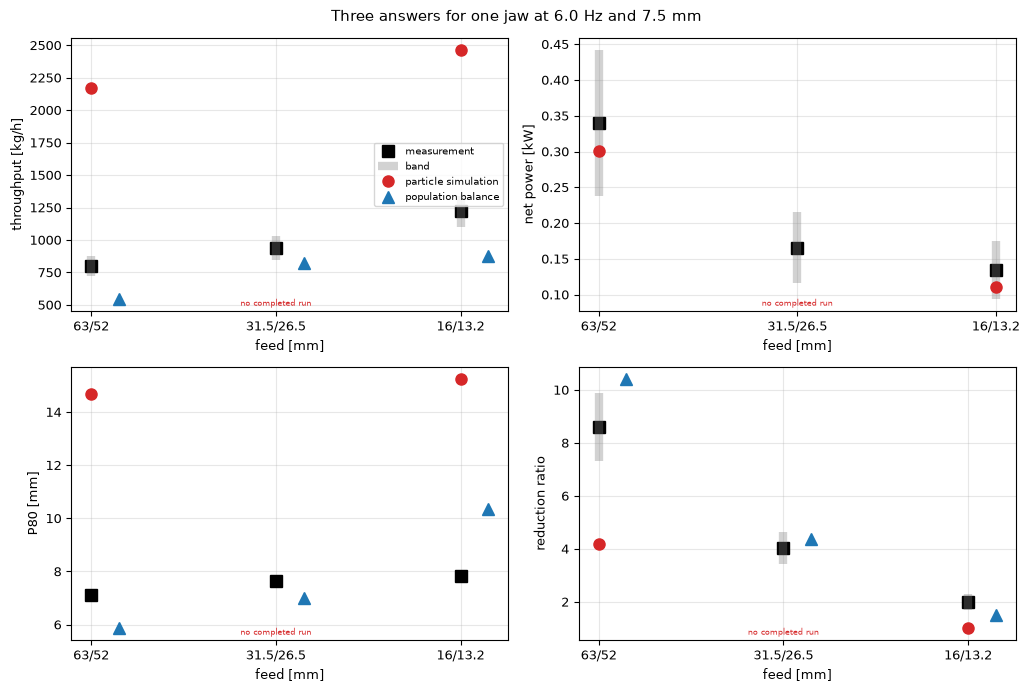

In [17]:
# Figure 1: the three sides at the three feeds, with the bands set before the runs and the standard error of the
# simulation
x = np.arange(len(feeds))
fig, axes = plt.subplots(2, 2, figsize=(10.4, 7.0))
panels = (("throughput_kg_h", "throughput [kg/h]", bands["throughput_relative"]),
          ("net_power_kw", "net power [kW]", bands["net_power_relative"]),
          ("p80_mm", "P80 [mm]", None),
          ("reduction_ratio", "reduction ratio", bands["reduction_ratio_relative"]))
for ax, (key, label, band) in zip(axes.ravel(), panels):
    raw = [points[fc]["measured"][key] for fc in feeds]
    meas = [v["value"] if isinstance(v, dict) else v for v in raw]
    sim = [points[fc]["simulation"][key] if points[fc]["simulation"]["status"] == "complete" else None for fc in feeds]
    ax.plot(x, meas, "ks", ms=8, label="measurement")
    if band:
        low, high = [v * (1 - band) for v in meas], [v * (1 + band) for v in meas]
        ax.vlines(x, low, high, color="gray", lw=6, alpha=0.35, label="band")
    have = [i for i, v in enumerate(sim) if v is not None]
    ax.plot(have, [sim[i] for i in have], "o", color="tab:red", ms=8, label="particle simulation")
    if key != "net_power_kw":
        ax.plot(x + 0.15, [points[fc]["population_balance"][key] for fc in feeds], "^", color="tab:blue", ms=8,
                label="population balance")
    edge = ax.get_xaxis_transform()
    for i in (i for i, v in enumerate(sim) if v is None):
        ax.text(i, 0.02, "no completed run", transform=edge, ha="center", fontsize=6, color="tab:red")
    ax.set_xticks(x)
    ax.set_xticklabels(feeds)
    ax.set_xlabel("feed [mm]")
    ax.set_ylabel(label)
axes[0, 0].legend(fontsize=7)
fig.suptitle("Three answers for one jaw at 6.0 Hz and 7.5 mm")
fig.tight_layout()
plt.show()

Reading figure 1. In throughput the simulation's markers lie far above the grey band of the measurement at the two feeds that have a run and the balance's markers lie below it at all three. In net power the simulation's markers are inside the 30 percent bar at both feeds and nothing else is plotted; the middle feed shows no marker and the label "no completed run". In P80 the simulation's markers are near 15 mm against 7 to 8 measured, and the balance's lie between 5.88 and 10.34 mm. In reduction ratio the markers of the balance are closest to the bar at the middle feed, which is the met verdict. The figure does not show the standard error of the simulation's means, too small to draw at these scales, nor the spread of the balance, which Figure 3 shows.

Figure 2 draws the cumulative product curves: the measured one, the balance's and the simulation's, where a particle run exists.

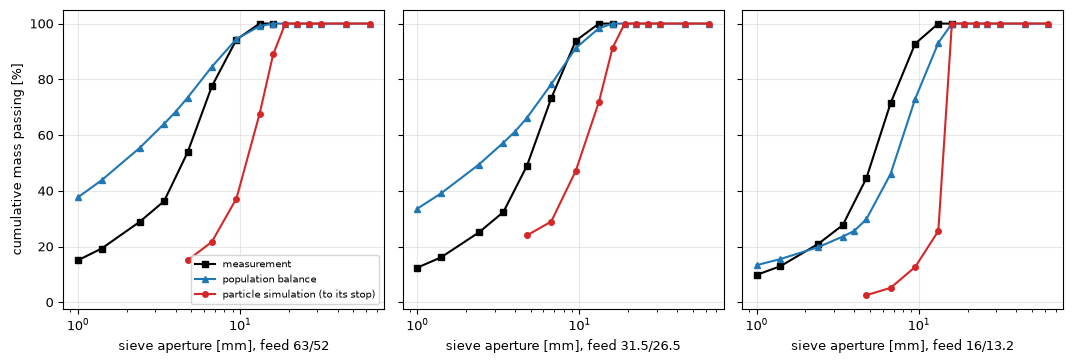

In [18]:
# Figure 2: the product curve of each side at each feed: measured, population balance and the committed particle run
fig, axes = plt.subplots(1, 3, figsize=(10.8, 3.7), sharey=True)
for ax, fc in zip(axes, feeds):
    pt = points[fc]
    meas_curve, pb_curve = pt["measured"]["product"], pt["population_balance"]["product"]
    ax.plot(meas_curve["sieves_mm"], meas_curve["passing_pct"], "ks-", ms=4, label="measurement")
    ax.plot(pb_curve["sieves_mm"], pb_curve["passing_pct"], "^-", color="tab:blue", ms=4, label="population balance")
    sim_product = pt["simulation"]["product"]
    if sim_product:
        sizes = [s for s, v in zip(sim_product["sieves_mm"], sim_product["passing_pct"]) if v is not None]
        values = [v for v in sim_product["passing_pct"] if v is not None]
        ax.plot(sizes, values, "o-", color="tab:red", ms=4, label="particle simulation (to its stop)")
    ax.set_xscale("log")
    ax.set_xlabel(f"sieve aperture [mm], feed {fc}")
axes[0].set_ylabel("cumulative mass passing [%]")
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

Reading figure 2. The measured curves reach 100 percent by the 13.2 to 16 mm sieves at every feed; the simulation's curves are displaced to the right of them by a factor of about two in size at the two feeds with a run, and its curve at the middle feed, which is the product of the run up to its stop and is not a compared value, is displaced as well. The balance's curves lie on the fine side of the measured ones at the coarse and the middle feed and on the coarse side at the fine feed; they do not bracket them. The figure does not show what happens below 1 mm, where the paper's markers stop, and the simulation's fines below its 4 mm minimum sphere are pooled in a single point.

The last cell of this section reads the evidence for why the three sides differ, from the document: the simulated product against the open side and against the measured top size, and the capacity model's terms.

In [19]:
# The evidence for why they differ, read from the document: the simulated product against the open side and the
# measured top size
print("feed  largest [mm]  above the open side  fines below 4 mm [%]  sim % below 13.2 mm  measured % below 13.2 mm")
for fc, pt in points.items():
    s, m = pt["simulation"], pt["measured"]["product"]
    sim_pass = "absent"
    if s["product"]:
        sim_pass = f"{s['product']['passing_pct'][s['product']['sieves_mm'].index(13.2)]:.1f}"
    meas_pass = m["passing_pct"][m["sieves_mm"].index(13.2)]
    print(f"{fc:>10s} {s['largest_product_mm']:12.1f} {s['spheres_above_open_side']:20d}",
          f"{s['fines_below_minimum_pct']:20.1f} {sim_pass:>18s} {meas_pass:23.1f}")
print(f"open side (closed side plus the throw, read as the bottom opening): {doc['settings']['oss_mm']} mm")
cap_doc = points["63/52"]["population_balance"]["capacity"]
shown = {k: (round(v, 4) if isinstance(v, float) else v) for k, v in cap_doc.items()}
print("capacity model, coarse feed:", shown)

feed  largest [mm]  above the open side  fines below 4 mm [%]  sim % below 13.2 mm  measured % below 13.2 mm
     63/52         18.1                    9                 13.6               67.6                   100.0
 31.5/26.5         17.2                    0                 22.6               72.0                   100.0
   16/13.2         16.0                    0                  1.9               25.6                   100.0
open side (closed side plus the throw, read as the bottom opening): 17.5 mm
capacity model, coarse feed: {'depth_m': 0.2038, 'critical_speed_rpm': 396.01, 'regime': 'below_critical_speed', 'volumetric_m3_h': 1.0627, 'feed_factor': 0.5237, 'throw_factor': 0.364, 'material_factor': 1.0, 'density_t_m3': 2.7}


Why they differ, said only from what is recorded and about the implementation of `crushdem` (the paper's own simulation matched the power and the throughput trend). The simulation's product is too coarse: only 67.6, 72.0 and 25.6 percent of it passes 13.2 mm at the three feeds (the middle value is the product of the run up to its stop), where the measured product is entirely below that size, and its largest spheres are 18.1, 17.2 and 16.0 mm, with 9 spheres of the coarse feed above the 17.5 mm open side. The package's validation record names seven candidate causes and tests none: the contact of Table 3, six times softer than the paper's own calibrated sphere, which lets spheres larger than the open side squeeze through by overlap; the reading of the 10 mm throw as the bottom opening, which makes an open side of 17.5 mm that the measured product, entirely below 13.2 mm, hardly reconciles with; the harmonic swing law and the 20 degree nip angle, which the paper does not give; the flat, smooth plates; the progeny law against the paper's fixed progeny set; the size effect extrapolated below 29 mm; and whole spheres passing the gap by diameter. The overlap is part of the same story: 18 of the 29 window strokes of the coarse feed and 17 of the 25 of the fine one exceed 0.3, so the means rest on strokes where the contact is already outside its assumption.

The population balance's throughput is below the measurement by 11.8 to 31.5 percent because it is Sastri's equation on the machine's geometry with a material factor of 1.0 that its authors ask to confirm, and one feed in three is inside the 20 percent that Sastri reports for his own data. Its product is not fitted either: the classification is a first estimate and the cone-crusher ranges of King, read next, bracket the measured P80 at all three feeds but move it by tens of percent. It states no power because the ore has no published work index, and the implied index is not constant across feeds. None of these reasons was tested by changing the model and rerunning; each is a reading of what the record holds.

### Where the comparison changes or breaks: the runs that did not complete, and the classification parameters

Two things limit what the comparison can say. The first is that a run which stops gives no verdict. The 31.5/26.5 mm feed stopped at both rungs of the ladder (notebook 02 prints the attempts), so five of its verdicts are not compared with the basis `run_incomplete`, and the document is `partial` for that reason: no sentence of this notebook states how the particle simulation does at the middle feed beyond the live batch of 0.5 kg, which completes, and the whole-run throughput of the stopped full-size run. The runs that did complete did so only at the second rung, with a large share of their strokes above the first, so that what the simulation says at the coarse and the fine feed rests on a contact outside the assumption of its model.

The second is the sensitivity of the balance to its three classification parameters, which it takes from a first estimate. The cell varies one at a time over King's cone-crusher range while the others stay at the first estimate, and prints the P80 at the two ends.

In [20]:
# Where it breaks: the P80 of the population balance against each of its three classification parameters, one at a
# time
grids = {"alpha1": np.linspace(0.5, 0.95, 8), "alpha2": np.linspace(1.7, 3.5, 8), "n": np.linspace(1.0, 3.0, 8)}
base = {"alpha1": 1.0, "alpha2": None, "n": labjaw.FIRST_ESTIMATE_K3}
sens = {}
for fc, pt in points.items():
    lo, hi = pt["feed_mm"]
    e50 = median_fracture_energy(labjaw.class_mean_mm(lo, hi) / 1000.0, ore)
    axb = labjaw.axb_from_fracture_energy(ore.a_max, ore.b_prime, e50)
    for name, grid in grids.items():
        p80s = []
        for value in grid:
            args = dict(base, **{name: float(value)})
            cls = labjaw.lab_classification(P.CSS_MM, P.THROW_MM, **args)
            p80s.append(labjaw.evaluate_lab_jaw(jaw, lo, hi, P.CSS_MM, P.SPEED_RPM, axb, classification=cls).p80_mm)
        sens[(fc, name)] = p80s
print("feed  parameter  P80 at its lowest value  at its highest  change [%]")
for (fc, name), p80s in sens.items():
    print(f"{fc:>10s} {name:>10s} {p80s[0]:23.2f} {p80s[-1]:15.2f} {100 * (p80s[-1] - p80s[0]) / p80s[0]:+11.1f}")

feed  parameter  P80 at its lowest value  at its highest  change [%]
     63/52     alpha1                    4.25            5.77       +35.8
     63/52     alpha2                    5.16            7.09       +37.5
     63/52          n                    6.89            5.62       -18.5
 31.5/26.5     alpha1                    5.09            6.83       +34.2
 31.5/26.5     alpha2                    6.06            9.34       +54.3
 31.5/26.5          n                    8.70            6.60       -24.1
   16/13.2     alpha1                    8.17           10.13       +24.0
   16/13.2     alpha2                    7.86           13.54       +72.2
   16/13.2          n                   13.48            9.49       -29.6


Each parameter moves the P80 by tens of percent over King's cone-crusher range; this is a sensitivity of the model to ranges given for cone crushers and not an uncertainty published for a jaw. At the coarse feed, $K_1/\mathrm{CSS}$ from 0.5 to 0.95 raises it from 4.25 to 5.77 mm (+35.8 percent), $K_2/\mathrm{CSS}$ from 1.7 to 3.5 from 5.16 to 7.09 (+37.5) and $K_3$ from 1 to 3 lowers it from 6.89 to 5.62 (-18.5). The effect grows as the feed gets finer: $K_2/\mathrm{CSS}$ moves the P80 of the fine feed by +72.2 percent, from 7.86 to 13.54 mm. A first estimate that cannot say which point of those ranges the laboratory jaw sits at cannot be expected to land within 15 percent of the measured reduction ratio, and it does not except at one feed. The cell below prints the eight-corner band of the document against the measured values.

In [21]:
# The eight-corner band of King's ranges, as the document records it, against the measured P80 and
# reduction ratio
print("feed  band of P80 [mm]  measured  inside  band of the reduction ratio  measured  inside")
for fc, pt in points.items():
    band, meas = pt["population_balance"]["band"], pt["measured"]
    lo_p, hi_p = band["p80_mm"]
    lo_r, hi_r = band["reduction_ratio"]
    inside_p = lo_p <= meas["p80_mm"] <= hi_p
    inside_r = lo_r <= meas["reduction_ratio"] <= hi_r
    print(f"{fc:>10s} {lo_p:6.2f} to {hi_p:6.2f} {meas['p80_mm']:9.2f} {str(inside_p):>7s}",
          f"{lo_r:9.2f} to {hi_r:6.2f} {meas['reduction_ratio']:10.2f} {str(inside_r):>7s}")

feed  band of P80 [mm]  measured  inside  band of the reduction ratio  measured  inside
     63/52   3.32 to   8.91      7.12    True      6.88 to  18.46       8.60    True
 31.5/26.5   3.78 to  13.11      7.62    True      2.34 to   8.12       4.02    True
   16/13.2   5.32 to  14.43      7.83    True      1.08 to   2.92       1.99    True


The band of the eight corners contains the measured P80 and the measured reduction ratio at all three feeds: 7.12 mm inside 3.32 to 8.91, 7.62 inside 3.78 to 13.11 and 7.83 inside 5.32 to 14.43, and the ratios 8.60, 4.02 and 1.99 inside 6.88 to 18.46, 2.34 to 8.12 and 1.08 to 2.92. This is a weaker statement than the verdict: the balance is consistent with the measurement within the spread of King's cone-crusher ranges, which is a sensitivity of the model and not an uncertainty published for a jaw, and that spread is wide enough, a factor of 2.7 from lowest to highest P80 at the coarse feed, to hold almost any product. Figure 3 draws the P80 against each parameter.

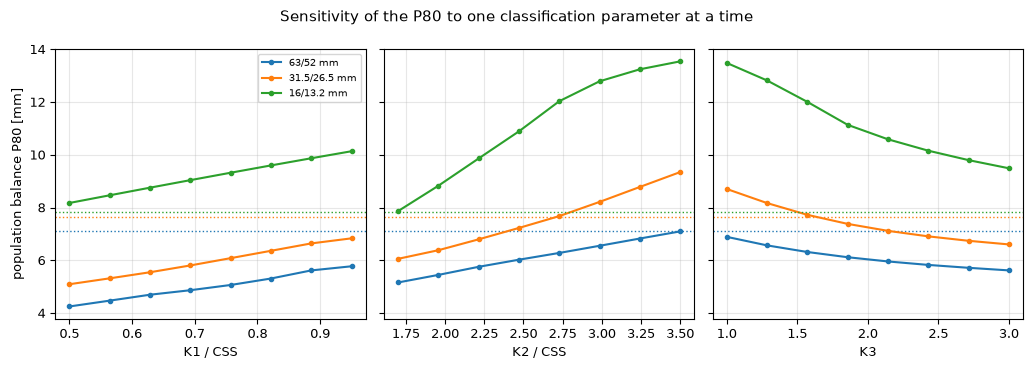

In [22]:
# Figure 3: the P80 of the population balance across the published range of each classification parameter; dotted:
# measured
fig, axes = plt.subplots(1, 3, figsize=(10.4, 3.7), sharey=True)
for ax, (name, grid) in zip(axes, grids.items()):
    for fc in feeds:
        line = ax.plot(grid, sens[(fc, name)], "o-", ms=3, label=f"{fc} mm")
        ax.axhline(points[fc]["measured"]["p80_mm"], color=line[0].get_color(), ls=":", lw=1)
    ax.set_xlabel({"alpha1": "K1 / CSS", "alpha2": "K2 / CSS", "n": "K3"}[name])
axes[0].set_ylabel("population balance P80 [mm]")
axes[0].legend(fontsize=7)
fig.suptitle("Sensitivity of the P80 to one classification parameter at a time")
fig.tight_layout()
plt.show()

Reading figure 3. The curves of the three feeds rise with $K_1/\mathrm{CSS}$ and $K_2/\mathrm{CSS}$ and fall with $K_3$. The middle feed's measured P80 of 7.62 mm is crossed by its curves against $K_2/\mathrm{CSS}$ and $K_3$, but the fine feed's curves stay above their measured P80 over every range (the closest is 7.86 mm against 7.83 mm, at $K_2/\mathrm{CSS}$ = 1.7) and the coarse feed's stay below theirs (5.16 to 7.09 mm against 7.12 mm, closest at $K_2/\mathrm{CSS}$ = 3.5), so no single value of one parameter puts the balance on the measurement at all three feeds. The figure moves one parameter at a time and does not show the interactions of the three, which the eight corners of the document do cover.

### Using it on your own data

The population balance side takes any laboratory jaw as a `LabJaw` (gape, width, throw, density, material factor) and any narrow feed class, and `evaluate_lab_jaw` returns the capacity, the product, the P80, the reduction ratio, the Bond term and the flags of the engine's checks; the ore enters as $A\,b$ from `axb_from_fracture_energy`. The cell evaluates another laboratory jaw, with the dimensions of the one that Donovan (2003) reports, a feed class of 45 to 31.5 mm, a closed side of 7.94 mm and 300 strokes per minute, with the ore of the paper standing in for yours.

The particle side of another point is a new operating point of the stage, `pipeline.dem.points.Point`, run by the command

```bash
python data-pipeline/run.py dem --runs <folder of the raw records> --output <folder>
```

which needs the precompute environment with `crushdem`, takes hours for a full batch, keeps each raw record under the folder, and writes the document and its replay files under `<folder>/dem/`. Without `--runs` the records go under `<CAOS_DATA_ROOT>/chancadem/dem-runs`, the rule the second printed line shows. A run that does not complete is recorded as it is. On the bake's machine the three feeds took about 45 minutes (63/52 mm), 6 minutes (31.5/26.5 mm, which stops) and 70 minutes (16/13.2 mm).

In [23]:
# Your own jaw: another laboratory machine and feed through the same module, and the stage's rule for its raw runs
other = labjaw.LabJaw(gape_mm=95.3, width_mm=146.1, throw_mm=6.35, density_t_m3=2.65, material_k3=1.0)
e50_other = median_fracture_energy(0.0375, ore)
axb_other = labjaw.axb_from_fracture_energy(ore.a_max, ore.b_prime, e50_other)
mine = labjaw.evaluate_lab_jaw(other, 31.5, 45.0, 7.94, 300.0, axb_other)
print(f"capacity {mine.throughput_kg_h:.0f} kg/h ({mine.capacity.branch}), P80 {mine.p80_mm:.2f} mm,",
      f"reduction ratio {mine.reduction_ratio:.2f}, mass closure {mine.mass_closure:.1e},",
      f"flags: {list(mine.flags)}")
folder = stage.runs_folder(None, {"CAOS_DATA_ROOT": "<data root>"})
print("raw runs folder when CAOS_DATA_ROOT is set:", folder.as_posix())
print("operating points of the bake:", [(pt.id, pt.feed_class, pt.capacity) for pt in P.POINTS])

capacity 700 kg/h (low-speed), P80 6.73 mm, reduction ratio 6.41, mass closure 2.2e-16, flags: []
raw runs folder when CAOS_DATA_ROOT is set: <data root>/chancadem/dem-runs
operating points of the bake: [('63-52', '63/52', 1500), ('31.5-26.5', '31.5/26.5', 1500), ('16-13.2', '16/13.2', 3000)]


The other jaw's capacity is 700 kg/h on the low-speed branch, with a P80 of 6.73 mm and a reduction ratio of 6.41; the mass closes to 2.2e-16 and no flag of the engine is raised. The point to take is what the output does not say: this is the population balance with the product's first estimate and the ore of another paper, a sensitivity to a different machine and not a prediction of Donovan's test. The second line shows the folder rule of the stage and the third the three operating points of the bake with their particle slots, 1500, 1500 and 3000.

## Results

**Answer:** At the three feeds the population balance with a jaw capacity model is the side nearer the measurement, and the particle simulation that loses is that of `crushdem` 0.6.0, not the discrete element method as the paper ran it: the paper's own simulation gave 0.32 kW against 0.34 kW measured and about 890 kg/h against 798.662 kg/h. The balance is nearer in 9 of 9 pairs of feed and quantity (6 of 6 where the particle simulation has a completed run), with throughputs of 546.98, 826.17 and 876.65 kg/h against 798.7, 937.2 and 1220.4 measured (errors of -31.5, -11.8 and -28.2 percent), while the 6 kg runs of `crushdem` pass 2167 and 2464 kg/h at the two feeds that completed (+171 and +102 percent). Nearer is not met: of the 16 verdicts that could be computed, 13 are outside their bands, set before the runs, and only 3 are inside, the simulation's two net power verdicts and the balance's reduction ratio at the middle feed (+9.0 percent against 15). The live batches of 0.5 kg at each feed point the same way and are not compared values.

The net power of the simulation, 0.3009 and 0.1108 kW against 0.34 and 0.1346 measured, is inside its 30 percent band for a reason that does not support the model: it draws 500 and 162 J/kg against 1533 and 397 measured while passing the batch 2.7 and 2.0 times too fast. The reasons are recorded and untested: for the simulation, a product that is twice as coarse as the measured one, with spheres above the open side, from a contact softer than the paper's own calibration and 18 of 29 window strokes above the overlap limit; for the balance, a capacity equation whose own check on Hersam's data reports deviations of less than 20 percent in most cases, and a first estimate of the classification whose sensitivity to King's cone-crusher ranges moves the P80 by 18 to 72 percent. The middle feed has no completed full-size particle run, and the document says so with state `partial`.

## Summary

- The jaw capacity model of Sastri (1994), computed by hand for the coarse feed, gives 546.98 kg/h, equal to the product's module and 31.5 percent below the measured 798.7 kg/h; its three throughputs are 11.8 to 31.5 percent below the measurement.
- The classification of the population balance is a first estimate with the ranges of King for cone crushers, used for want of jaw values; the eight-corner band contains the measured P80 and reduction ratio at all three feeds, and each parameter moves the P80 by 18 to 72 percent over its range, a sensitivity and not a published uncertainty. The engine's energy rule, written for the cone engine, is applied unchanged.
- The measured energy implies a work index of 3.08 to 5.45 kWh/t, not one value, so Bond's size term gives no power; the balance states none.
- The particle simulation of `crushdem` 0.6.0, run live on small batches and read at full size, passes the batch 2.7 and 2.0 times too fast with a product about twice as coarse, and its two met power verdicts rest on an energy per kilogram 67 and 59 percent low; the paper's own simulation matched the power and the throughput.
- The population balance is nearer the measurement in every comparable pair but meets its band in only 1 of 6; of 27 verdicts, 13 are not met, 3 are met and 11 are not compared.
- The middle feed has no completed full-size particle run: the comparison there is the balance against the measurement.

## References

- Austin, L. G., Klimpel, R. R., Luckie, P. T. (1984). Process engineering of size reduction: ball milling. SME-AIME. https://search.worldcat.org/title/11603131
- Barrios, G. K., Jiménez-Herrera, N., Fuentes-Torres, S. N., Tavares, L. M. (2020). DEM simulation of laboratory-scale jaw crushing of a gold-bearing ore using a particle replacement model. Minerals 10(8), 717. https://doi.org/10.3390/min10080717
- Bond, F. C. (1952). The third theory of comminution. Transactions AIME 193, 484-494. https://onemine.org/documents/the-third-theory-of-comminution
- Cleary, P. W., Sinnott, M. D. (2015). Simulation of particle flows and breakage in crushers using DEM: Part 1, Compression crushers. Minerals Engineering 74, 178-197. https://doi.org/10.1016/j.mineng.2014.10.021
- Donovan, J. G. (2003). Fracture toughness based models for the prediction of power consumption, product size, and capacity of jaw crushers. PhD thesis, Virginia Tech. https://vtechworks.lib.vt.edu/handle/10919/28544
- King, R. P. (2000). Technical Notes 5, Crushers. https://www.911metallurgist.com/wp-content/uploads/2017/04/Crushers.pdf
- Santibanez-Leal, F. (2026). crushdem 0.6.0, package page and README, with the validation record of the laboratory jaw. https://pypi.org/project/crushdem/
- Sastri, S. R. S. (1994). Capacities and performance characteristics of jaw crushers. Minerals and Metallurgical Processing, May 1994, 80-85. https://www.911metallurgist.com/wp-content/uploads/2016/02/Capacities-and-Sizing-of-jaw-crushers.pdf
- Tavares, L. M. (2022). Review and further validation of a practical single-particle breakage model. KONA Powder and Particle Journal 39, 62-83. https://doi.org/10.14356/kona.2022012
- Whiten, W. J. (1972). The simulation of crushing plants with models developed using multiple spline regression. Journal of the South African Institute of Mining and Metallurgy 72(10), 257-264. https://www.saimm.co.za/Conferences/Apcom72/317-Whiten.pdf